Homework 1 — Black-Scholes-Merton Model

Option Basics and BSM

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

Question (a) — Customizable Plotter

Explanation of the improvements.

In [13]:
def my_plotter(x, y, layout=None, names=None):
    """Plot one curve or a sequence of curves against a shared x array."""
    layout = {} if layout is None else dict(layout)
    x = np.asarray(x)
    y = np.asarray(y)
    if y.ndim == 1:
        y = y[np.newaxis, :]
    if x.ndim != 1 or y.ndim != 2 or y.shape[1] != x.size:
        raise ValueError("Use a 1D x array and curves with the same length as x.")
    if names is not None and len(names) != len(y):
        raise ValueError("Provide one name per curve.")
    colors = layout.get("colors")
    if colors is not None and len(colors) < len(y):
        raise ValueError("Provide at least one color per curve.")
    fig, ax = plt.subplots(figsize=layout.get("figsize", (9, 5)))
    for i, curve in enumerate(y):
        ax.plot(x, curve,
                label=None if names is None else names[i],
                color=None if colors is None else colors[i],
                linewidth=layout.get("linewidth", 2),
                linestyle=layout.get("styles", ["-"])[
                    i % len(layout.get("styles", ["-"]))],
                marker=layout.get("marker", None),
                alpha=layout.get("alpha", 1.0))
    ax.set_title(layout.get("title", ""),
                 fontsize=layout.get("title_fontsize", 16),
                 pad=layout.get("titlepad", 15))
    ax.set_xlabel(layout.get("x_label", ""), fontsize=layout.get("label_fontsize", 12))
    ax.set_ylabel(layout.get("y_label", ""), fontsize=layout.get("label_fontsize", 12))
    ax.tick_params(labelsize=layout.get("tick_fontsize", 10))
    ax.grid(layout.get("grid", True), alpha=0.3)
    if layout.get("zero_line", True):
        ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    if "xlim" in layout:
        ax.set_xlim(layout["xlim"])
    if "ylim" in layout:
        ax.set_ylim(layout["ylim"])
    if names is not None and layout.get("legend", True):
        ax.legend(loc=layout.get("legend_loc", "best"),
                  fontsize=layout.get("legend_fontsize", 10))
    fig.tight_layout()
    if layout.get("save_path"):
        fig.savefig(layout["save_path"], dpi=layout.get("dpi", 150), bbox_inches="tight")
    plt.show()
    return fig, ax

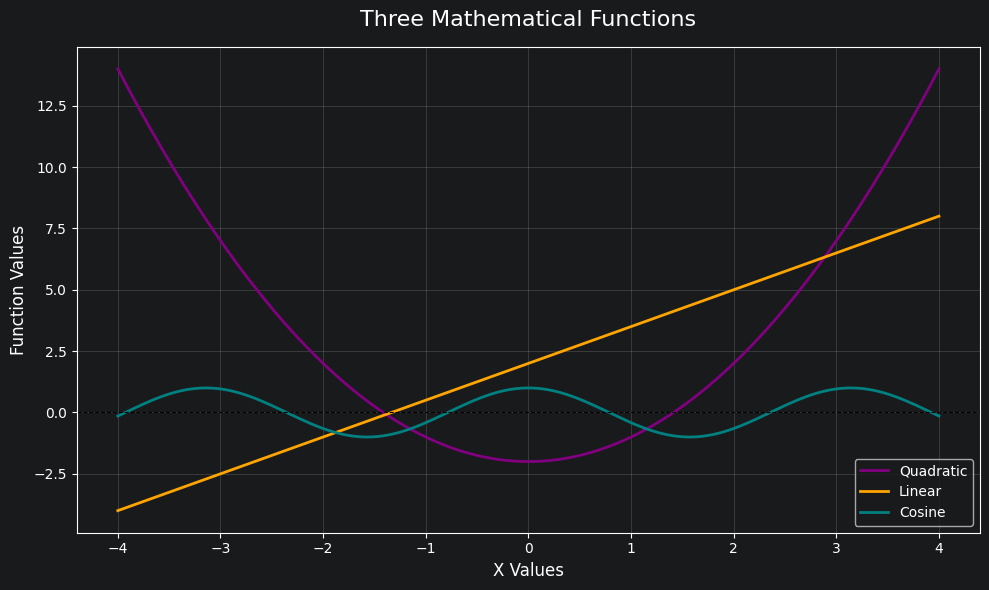

(<Figure size 1000x600 with 1 Axes>,
 <Axes: title={'center': 'Three Mathematical Functions'}, xlabel='X Values', ylabel='Function Values'>)

In [14]:

# Question (a) - Testing the customizable plotter

x = np.linspace(-4, 4, 150)

# Three different mathematical functions
y1 = x**2 - 2
y2 = 1.5*x + 2
y3 = np.cos(2*x)

my_plotter(
    x,
    [y1, y2, y3],
    names=["Quadratic", "Linear", "Cosine"],
    layout={
        "title": "Three Mathematical Functions",
        "x_label": "X Values",
        "y_label": "Function Values",
        "figsize": (10, 6),
        "colors": ["purple", "orange", "teal"],
        "linewidth": 2,
        "grid": True
    }
)



## Question (b) - BSM Call Option and Greeks

In this task, I extend the Black-Scholes-Merton
call option pricing function to calculate the
option price and its Greeks:

- Delta
- Gamma
- Vega
- Theta
- Rho


In [15]:

import numpy as np
from scipy.stats import norm

def black_scholes_eur_call(r, T, S0, sigma, K, return_greeks=False):
    """
    European Call Option - Black-Scholes-Merton
    Returns the call price and optionally the Greeks.
    """

    if T <= 0 or sigma <= 0 or S0 <= 0:
        raise ValueError("T, sigma and S0 must be positive")

    K = np.asarray(K, dtype=float)

    if np.any(K <= 0):
        raise ValueError("Strike price must be positive")

    # Step 1: Calculate d1 and d2
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    # Step 2: Calculate Call Option Price
    call_price = S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

    if not return_greeks:
        return call_price

    # Step 3: Calculate the Greeks
    delta = norm.cdf(d1)

    gamma = norm.pdf(d1) / (S0 * sigma * np.sqrt(T))

    vega = S0 * norm.pdf(d1) * np.sqrt(T)

    theta = -(S0 * norm.pdf(d1) * sigma) / (2 * np.sqrt(T)) - r * K * np.exp(-r * T) * norm.cdf(d2)

    rho = K * T * np.exp(-r * T) * norm.cdf(d2)

    return {
        "Call Price": call_price,
        "Delta": delta,
        "Gamma": gamma,
        "Vega": vega,
        "Theta": theta,
        "Rho": rho
    }


In [16]:

# Test BSM Call Option and Greeks

results = black_scholes_eur_call(
    r=0.05,
    T=1,
    S0=100,
    sigma=0.20,
    K=100,
    return_greeks=True
)

for name, value in results.items():
    print(f"{name}: {float(value):.4f}")


Call Price: 10.4506
Delta: 0.6368
Gamma: 0.0188
Vega: 37.5240
Theta: -6.4140
Rho: 53.2325



## Question (c) - European Put Option Pricing

In this task, I implement the Black-Scholes-Merton
formula to calculate the price of a European put option.

The model assumes a non-dividend-paying stock.


In [17]:

# Question (c) - European Put Option

def black_scholes_eur_put(r, T, S0, sigma, K):
    """
    Calculate the European put option price
    using the Black-Scholes-Merton model.
    """

    if T <= 0 or sigma <= 0 or S0 <= 0:
        raise ValueError("T, sigma and S0 must be positive")

    K = np.asarray(K, dtype=float)

    if np.any(K <= 0):
        raise ValueError("Strike price must be positive")

    # Calculate d1 and d2
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    # Calculate European Put Price
    put_price = K * np.exp(-r * T) * norm.cdf(-d2) - S0 * norm.cdf(-d1)

    return put_price


In [18]:

# Test European Put Option

put_price = black_scholes_eur_put(
    r=0.05,
    T=1,
    S0=100,
    sigma=0.20,
    K=100
)

print(f"European Put Option Price: {float(put_price):.4f}")


European Put Option Price: 5.5735



## Question (d) - Put-Call Parity

In this task, I verify the put-call parity relationship
using the Black-Scholes-Merton call and put pricing functions.

For European options on a non-dividend-paying stock:

C - P = S0 - K * exp(-rT)

I compare both sides of the equation to check
whether put-call parity holds.


In [19]:

# Question (d) - Put-Call Parity Verification

# Model parameters
S0 = 100
K = 100
r = 0.05
T = 1
sigma = 0.20

# Calculate Call and Put prices
call_price = black_scholes_eur_call(r, T, S0, sigma, K)

put_price = black_scholes_eur_put(r, T, S0, sigma, K)

# Verify put-call parity
left_side = call_price - put_price
right_side = S0 - K * np.exp(-r * T)

# Display the results
print(f"Call Price: {float(call_price):.4f}")
print(f"Put Price: {float(put_price):.4f}")
print(f"Left Side (C - P): {float(left_side):.4f}")
print(f"Right Side: {float(right_side):.4f}")

# Check equality with numerical tolerance
if np.allclose(left_side, right_side, atol=1e-8):
    print("Put-Call Parity Holds!")
else:
    print("Put-Call Parity Does Not Hold!")


Call Price: 10.4506
Put Price: 5.5735
Left Side (C - P): 4.8771
Right Side: 4.8771
Put-Call Parity Holds!
